In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

DATA_PATH = Path("../data/himalayan_landslide_v1_dataset.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(df["LANDSLIDE"].value_counts())

print("\nMissing values:")
print(df.isnull().sum().sum())

Dataset shape: (23018, 7)

Columns:
['LATITUDE', 'LONGITUDE', 'ELEVATION', 'SLOPE', 'RAINFALL', 'LANDCOVER_CODE', 'LANDSLIDE']

Target distribution:
LANDSLIDE
1    11509
0    11509
Name: count, dtype: int64

Missing values:
0


In [2]:
from sklearn.model_selection import GroupShuffleSplit

# Input features and target
X = df.drop(columns=["LANDSLIDE"])
y = df["LANDSLIDE"]

# Assign each point to a 0.5° geographic block
block_size = 0.5

groups = (
    (np.floor(df["LATITUDE"] / block_size).astype(int).astype(str))
    + "_"
    + (np.floor(df["LONGITUDE"] / block_size).astype(int).astype(str))
)

# Split by geographic block, not individual rows
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

print("\nTrain geographic blocks:", groups.iloc[train_idx].nunique())
print("Test geographic blocks:", groups.iloc[test_idx].nunique())
print("Overlapping blocks:", len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))

Training rows: 17084
Testing rows: 5934

Training target distribution:
LANDSLIDE
0    0.503
1    0.497
Name: proportion, dtype: float64

Testing target distribution:
LANDSLIDE
1    0.508
0    0.492
Name: proportion, dtype: float64

Train geographic blocks: 49
Test geographic blocks: 13
Overlapping blocks: 0


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

numeric_features = ["ELEVATION", "SLOPE", "RAINFALL"]
categorical_features = ["LANDCOVER_CODE"]

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values(
    by="ROC-AUC", ascending=False
).reset_index(drop=True)

print(results_df.round(4).to_string(index=False))

               Model  Accuracy  ROC-AUC  PR-AUC  Precision  Recall     F1
       Random Forest    0.7861   0.8611  0.8441     0.7548  0.8573 0.8028
HistGradientBoosting    0.7696   0.8567  0.8444     0.7580  0.8025 0.7796
 Logistic Regression    0.7425   0.8331  0.8206     0.7053  0.8467 0.7695


Classification Report:
              precision    recall  f1-score   support

           0     0.8288    0.7128    0.7664      2921
           1     0.7548    0.8573    0.8028      3013

    accuracy                         0.7861      5934
   macro avg     0.7918    0.7850    0.7846      5934
weighted avg     0.7912    0.7861    0.7849      5934

Confusion Matrix:


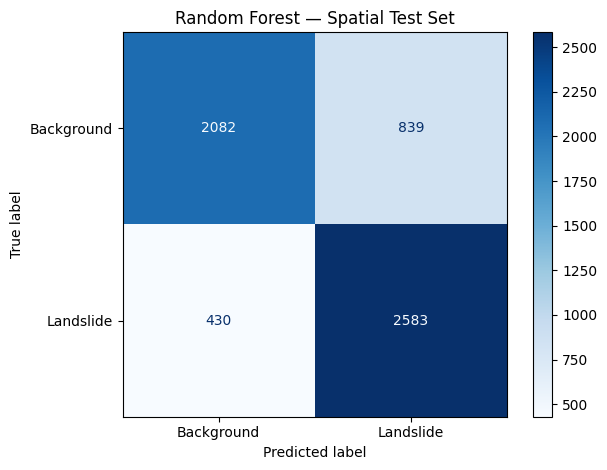

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

best_model = trained_models["Random Forest"]

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred, digits=4))

print("Confusion Matrix:")
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Background", "Landslide"],
    cmap="Blues"
)
plt.title("Random Forest — Spatial Test Set")
plt.tight_layout()
plt.show()

       Feature  Importance    Std
     ELEVATION      0.2131 0.0085
         SLOPE      0.0825 0.0051
LANDCOVER_CODE      0.0392 0.0013
      RAINFALL      0.0170 0.0027
      LATITUDE      0.0000 0.0000
     LONGITUDE      0.0000 0.0000


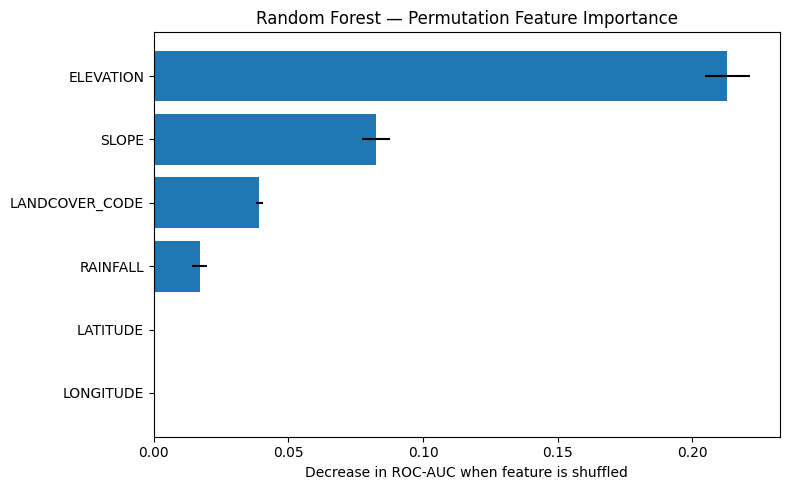

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

best_model = trained_models["Random Forest"]

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Importance", ascending=False)

print(importance_df.round(4).to_string(index=False))

plt.figure(figsize=(8, 5))
plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1],
    xerr=importance_df["Std"][::-1]
)
plt.xlabel("Decrease in ROC-AUC when feature is shuffled")
plt.title("Random Forest — Permutation Feature Importance")
plt.tight_layout()
plt.show()

In [6]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from scipy.stats import randint

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

param_dist = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_split": randint(2, 20),
    "model__min_samples_leaf": randint(2, 15),
    "model__max_features": ["sqrt", 0.7, 1.0]
}

search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_dist,
    n_iter=20,
    scoring="roc_auc",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

print("Best parameters:")
print(search.best_params_)
print("\nBest CV ROC-AUC:", round(search.best_score_, 4))

tuned_model = search.best_estimator_
tuned_prob = tuned_model.predict_proba(X_test)[:, 1]
tuned_pred = tuned_model.predict(X_test)

from sklearn.metrics import roc_auc_score, average_precision_score, f1_score

print("\nSpatial test results:")
print("ROC-AUC:", round(roc_auc_score(y_test, tuned_prob), 4))
print("PR-AUC:", round(average_precision_score(y_test, tuned_prob), 4))
print("F1-score:", round(f1_score(y_test, tuned_pred), 4))

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best parameters:
{'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 13, 'model__min_samples_split': 18, 'model__n_estimators': 500}

Best CV ROC-AUC: 0.8574

Spatial test results:
ROC-AUC: 0.8642
PR-AUC: 0.8511
F1-score: 0.8045


In [7]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
import pandas as pd
import numpy as np

# Create spatial groups for the training data
block_size = 0.5

train_groups = (
    np.floor(X_train["LATITUDE"] / block_size).astype(int).astype(str)
    + "_"
    + np.floor(X_train["LONGITUDE"] / block_size).astype(int).astype(str)
)

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

spatial_results = []

for fold, (tr_idx, val_idx) in enumerate(
    cv.split(X_train, y_train, groups=train_groups), start=1
):
    model = clone(tuned_model)

    X_tr = X_train.iloc[tr_idx]
    X_val = X_train.iloc[val_idx]
    y_tr = y_train.iloc[tr_idx]
    y_val = y_train.iloc[val_idx]

    model.fit(X_tr, y_tr)

    probabilities = model.predict_proba(X_val)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    spatial_results.append({
        "Fold": fold,
        "Train blocks": train_groups.iloc[tr_idx].nunique(),
        "Validation blocks": train_groups.iloc[val_idx].nunique(),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "PR-AUC": average_precision_score(y_val, probabilities),
        "F1": f1_score(y_val, predictions)
    })

spatial_results_df = pd.DataFrame(spatial_results)

print(spatial_results_df.round(4).to_string(index=False))
print("\nMean scores:")
print(spatial_results_df[["ROC-AUC", "PR-AUC", "F1"]].mean().round(4))
print("\nStandard deviation:")
print(spatial_results_df[["ROC-AUC", "PR-AUC", "F1"]].std().round(4))

 Fold  Train blocks  Validation blocks  ROC-AUC  PR-AUC     F1
    1            41                  8   0.8864  0.8661 0.7967
    2            38                 11   0.8540  0.8427 0.7738
    3            38                 11   0.8760  0.8688 0.7994
    4            39                 10   0.8912  0.8646 0.8206
    5            40                  9   0.8945  0.8772 0.8384

Mean scores:
ROC-AUC    0.8804
PR-AUC     0.8639
F1         0.8058
dtype: float64

Standard deviation:
ROC-AUC    0.0163
PR-AUC     0.0128
F1         0.0247
dtype: float64


In [8]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import StratifiedGroupKFold
import numpy as np
import pandas as pd

spatial_features = ["LATITUDE", "LONGITUDE"]

block_size = 0.5
train_groups = (
    np.floor(X_train["LATITUDE"] / block_size).astype(int).astype(str)
    + "_"
    + np.floor(X_train["LONGITUDE"] / block_size).astype(int).astype(str)
)

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

comparison = []

for name, features in {
    "Geographic baseline": spatial_features,
    "Full susceptibility model": list(X_train.columns)
}.items():

    fold_auc = []
    fold_ap = []

    for tr_idx, val_idx in cv.split(
        X_train[features], y_train, groups=train_groups
    ):
        model = clone(tuned_model) if name == "Full susceptibility model" else Pipeline([
            ("scale", StandardScaler()),
            ("model", LogisticRegression(max_iter=1000, random_state=42))
        ])

        model.fit(X_train.iloc[tr_idx][features], y_train.iloc[tr_idx])
        probabilities = model.predict_proba(
            X_train.iloc[val_idx][features]
        )[:, 1]

        fold_auc.append(roc_auc_score(y_train.iloc[val_idx], probabilities))
        fold_ap.append(
            average_precision_score(y_train.iloc[val_idx], probabilities)
        )

    comparison.append({
        "Model": name,
        "Mean ROC-AUC": np.mean(fold_auc),
        "Mean PR-AUC": np.mean(fold_ap)
    })

print(pd.DataFrame(comparison).round(4).to_string(index=False))

                    Model  Mean ROC-AUC  Mean PR-AUC
      Geographic baseline        0.6477       0.5587
Full susceptibility model        0.8804       0.8639


In [11]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, average_precision_score
import numpy as np
import pandas as pd

feature_sets = {
    "Full model": list(X_train.columns),
    "Without elevation": [
        c for c in X_train.columns if c != "ELEVATION"
    ],
    "Terrain and land cover": [
        "SLOPE", "LANDCOVER_CODE", "RAINFALL"
    ]
}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

groups = (
    np.floor(X_train["LATITUDE"] / 0.5).astype(int).astype(str)
    + "_"
    + np.floor(X_train["LONGITUDE"] / 0.5).astype(int).astype(str)
)

results = []

for name, features in feature_sets.items():
    auc_scores, ap_scores = [], []

    numeric = [
        c for c in features
        if c != "LANDCOVER_CODE"
    ]
    categorical = [
        c for c in features
        if c == "LANDCOVER_CODE"
    ]

    transformers = []

    if numeric:
        transformers.append((
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric
        ))

    if categorical:
        transformers.append((
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical
        ))

    for tr_idx, val_idx in cv.split(X_train, y_train, groups):
        model = Pipeline([
            ("preprocessor", ColumnTransformer(transformers)),
            ("model", clone(tuned_model.named_steps["model"]))
        ])

        X_tr = X_train.iloc[tr_idx][features]
        X_val = X_train.iloc[val_idx][features]
        y_tr = y_train.iloc[tr_idx]
        y_val = y_train.iloc[val_idx]

        model.fit(X_tr, y_tr)
        probabilities = model.predict_proba(X_val)[:, 1]

        auc_scores.append(roc_auc_score(y_val, probabilities))
        ap_scores.append(average_precision_score(y_val, probabilities))

    results.append({
        "Feature set": name,
        "Mean ROC-AUC": np.mean(auc_scores),
        "Mean PR-AUC": np.mean(ap_scores)
    })

print(pd.DataFrame(results).round(4).to_string(index=False))

           Feature set  Mean ROC-AUC  Mean PR-AUC
            Full model        0.8761       0.8546
     Without elevation        0.8000       0.7775
Terrain and land cover        0.8102       0.7869


In [12]:
from pathlib import Path
import joblib

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

final_model = search.best_estimator_

artifact = {
    "model": final_model,
    "features": list(X_train.columns),
    "target": "LANDSLIDE",
    "threshold": 0.5,
    "model_name": "Tuned Random Forest",
    "spatial_block_size_degrees": 0.5
}

model_path = MODEL_DIR / "landslide_susceptibility_model.joblib"
joblib.dump(artifact, model_path)

print("Saved model to:", model_path.resolve())
print("Features:", artifact["features"])

Saved model to: C:\Users\imman\OneDrive\Desktop\Project\ML Project\himalyan-landslide-prediction\models\landslide_susceptibility_model.joblib
Features: ['LATITUDE', 'LONGITUDE', 'ELEVATION', 'SLOPE', 'RAINFALL', 'LANDCOVER_CODE']


In [13]:
import joblib
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

artifact = joblib.load(
    "../models/landslide_susceptibility_model.joblib"
)

final_model = artifact["model"]

y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

ROC-AUC: 0.8642
PR-AUC: 0.8511

Classification Report:
              precision    recall  f1-score   support

           0     0.8504    0.6751    0.7527      2921
           1     0.7375    0.8848    0.8045      3013

    accuracy                         0.7816      5934
   macro avg     0.7939    0.7800    0.7786      5934
weighted avg     0.7930    0.7816    0.7790      5934

Confusion Matrix:
[[1972  949]
 [ 347 2666]]


In [14]:
import pandas as pd
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix
)

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]

threshold_results = []

for threshold in thresholds:
    predictions = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "False Positives": fp,
        "False Negatives": fn
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4).to_string(index=False))

 Threshold  Precision  Recall     F1  False Positives  False Negatives
      0.30     0.6977  0.9406 0.8011             1228              179
      0.35     0.7096  0.9293 0.8047             1146              213
      0.40     0.7187  0.9167 0.8057             1081              251
      0.45     0.7269  0.8991 0.8039             1018              304
      0.50     0.7375  0.8848 0.8045              949              347
      0.55     0.7520  0.8636 0.8040              858              411
      0.60     0.7648  0.8297 0.7959              769              513
      0.65     0.7842  0.7730 0.7785              641              684
      0.70     0.8173  0.6784 0.7414              457              969


In [15]:
import joblib

MODEL_PATH = "../models/landslide_susceptibility_model.joblib"

artifact = joblib.load(MODEL_PATH)
artifact["threshold"] = 0.40

joblib.dump(artifact, MODEL_PATH)

print("Saved threshold:", artifact["threshold"])

Saved threshold: 0.4


In [16]:
import pandas as pd
import numpy as np

# Model scores for the training data
train_scores = final_model.predict_proba(X_train)[:, 1]

# Derive class boundaries from training scores only
boundaries = np.quantile(train_scores, [0.25, 0.50, 0.75])

print("Low / Moderate boundary:", round(boundaries[0], 4))
print("Moderate / High boundary:", round(boundaries[1], 4))
print("High / Very High boundary:", round(boundaries[2], 4))

def susceptibility_class(score):
    if score <= boundaries[0]:
        return "Low"
    elif score <= boundaries[1]:
        return "Moderate"
    elif score <= boundaries[2]:
        return "High"
    else:
        return "Very High"

print("\nTraining score distribution:")
print(pd.Series(train_scores).describe().round(4))

Low / Moderate boundary: 0.1352
Moderate / High boundary: 0.6194
High / Very High boundary: 0.778

Training score distribution:
count    17084.0000
mean         0.4987
std          0.3243
min          0.0042
25%          0.1352
50%          0.6194
75%          0.7780
max          0.9820
dtype: float64


In [20]:
import pandas as pd
import numpy as np

# 1. Test class distribution
class_order = ["Low", "Moderate", "High", "Very High"]

print("TEST CLASS DISTRIBUTION")
print(test_classes.value_counts().reindex(class_order, fill_value=0))

print("\nTEST CLASS DISTRIBUTION (%)")
percentages = (
    test_classes.value_counts()
    .reindex(class_order, fill_value=0)
    .div(len(test_classes))
    .mul(100)
)
print(percentages.round(2).to_string())

# 2. Actual landslide rate in each class
test_class_analysis = pd.DataFrame({
    "Class": np.asarray(test_classes),
    "Actual": y_test.to_numpy()
})

summary = test_class_analysis.groupby(
    "Class", observed=False
)["Actual"].agg(
    Samples="count",
    Landslide_Samples="sum",
    Landslide_Rate="mean"
).reindex(class_order)

summary["Landslide_Rate_%"] = (
    summary["Landslide_Rate"] * 100
).round(2)

print("\nLANDSLIDE RATE BY SUSCEPTIBILITY CLASS")
print(summary.drop(columns="Landslide_Rate").to_string())

TEST CLASS DISTRIBUTION
Low          1444
Moderate     1317
High         1667
Very High    1506
Name: count, dtype: int64

TEST CLASS DISTRIBUTION (%)
Low          24.33
Moderate     22.19
High         28.09
Very High    25.38

LANDSLIDE RATE BY SUSCEPTIBILITY CLASS
           Samples  Landslide_Samples  Landslide_Rate_%
Class                                                  
Low           1444                 78              5.40
Moderate      1317                483             36.67
High          1667               1135             68.09
Very High     1506               1317             87.45


In [21]:
import joblib

MODEL_PATH = "../models/landslide_susceptibility_model.joblib"

artifact = joblib.load(MODEL_PATH)

artifact["susceptibility_classes"] = {
    "Low": [None, float(boundaries[0])],
    "Moderate": [float(boundaries[0]), float(boundaries[1])],
    "High": [float(boundaries[1]), float(boundaries[2])],
    "Very High": [float(boundaries[2]), None]
}

joblib.dump(artifact, MODEL_PATH)

print("Saved susceptibility class boundaries:")
for name, limits in artifact["susceptibility_classes"].items():
    print(f"{name}: {limits}")

Saved susceptibility class boundaries:
Low: [None, 0.13515920713119017]
Moderate: [0.13515920713119017, 0.6193833378037541]
High: [0.6193833378037541, 0.7780120651327762]
Very High: [0.7780120651327762, None]


In [22]:
import joblib
import pandas as pd
from pathlib import Path

MODEL_PATH = Path("../models/landslide_susceptibility_model.joblib")

artifact = joblib.load(MODEL_PATH)
model = artifact["model"]
features = artifact["features"]
boundaries = artifact["susceptibility_classes"]

def predict_susceptibility(
    latitude,
    longitude,
    elevation,
    slope,
    rainfall,
    landcover_code
):
    input_data = pd.DataFrame([{
        "LATITUDE": latitude,
        "LONGITUDE": longitude,
        "ELEVATION": elevation,
        "SLOPE": slope,
        "RAINFALL": rainfall,
        "LANDCOVER_CODE": landcover_code
    }])[features]

    score = float(model.predict_proba(input_data)[0, 1])

    if score <= boundaries["Low"][1]:
        category = "Low"
    elif score <= boundaries["Moderate"][1]:
        category = "Moderate"
    elif score <= boundaries["High"][1]:
        category = "High"
    else:
        category = "Very High"

    return {
        "model_score": round(score, 4),
        "susceptibility_class": category
    }

In [23]:
sample = df.iloc[0]

result = predict_susceptibility(
    latitude=sample["LATITUDE"],
    longitude=sample["LONGITUDE"],
    elevation=sample["ELEVATION"],
    slope=sample["SLOPE"],
    rainfall=sample["RAINFALL"],
    landcover_code=sample["LANDCOVER_CODE"]
)

print(result)

{'model_score': 0.4664, 'susceptibility_class': 'Moderate'}


In [24]:
import json
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

report = {
    "model": "Tuned Random Forest",
    "test_samples": int(len(y_test)),
    "spatial_test_metrics": {
        "accuracy": round(accuracy_score(y_test, y_pred), 4),
        "roc_auc": round(roc_auc_score(y_test, y_prob), 4),
        "pr_auc": round(average_precision_score(y_test, y_prob), 4),
        "precision": round(precision_score(y_test, y_pred), 4),
        "recall": round(recall_score(y_test, y_pred), 4),
        "f1_score": round(f1_score(y_test, y_pred), 4)
    },
    "decision_threshold": 0.40,
    "class_boundaries": {
        key: value for key, value in artifact["susceptibility_classes"].items()
    },
    "limitations": [
        "Background samples are not confirmed landslide-free.",
        "Scores are not calibrated real-world probabilities.",
        "Static features do not predict imminent landslide events."
    ]
}

output_path = Path("../models/susceptibility_evaluation.json")
output_path.parent.mkdir(parents=True, exist_ok=True)

with open(output_path, "w", encoding="utf-8") as file:
    json.dump(report, file, indent=4)

print(json.dumps(report, indent=4))
print("\nSaved evaluation report to:", output_path.resolve())

{
    "model": "Tuned Random Forest",
    "test_samples": 5934,
    "spatial_test_metrics": {
        "accuracy": 0.7816,
        "roc_auc": 0.8642,
        "pr_auc": 0.8511,
        "precision": 0.7375,
        "recall": 0.8848,
        "f1_score": 0.8045
    },
    "decision_threshold": 0.4,
    "class_boundaries": {
        "Low": [
            null,
            0.13515920713119017
        ],
        "Moderate": [
            0.13515920713119017,
            0.6193833378037541
        ],
        "High": [
            0.6193833378037541,
            0.7780120651327762
        ],
        "Very High": [
            0.7780120651327762,
            null
        ]
    },
    "limitations": [
        "Background samples are not confirmed landslide-free.",
        "Scores are not calibrated real-world probabilities.",
        "Static features do not predict imminent landslide events."
    ]
}

Saved evaluation report to: C:\Users\imman\OneDrive\Desktop\Project\ML Project\himalyan-landslide-

In [25]:
import json
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

threshold = 0.40
y_pred_40 = (y_prob >= threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred_40, labels=[0, 1]
).ravel()

report_path = Path("../models/susceptibility_evaluation.json")

with open(report_path, "r", encoding="utf-8") as file:
    report = json.load(file)

report["decision_threshold"] = threshold
report["spatial_test_metrics"].update({
    "accuracy": round(accuracy_score(y_test, y_pred_40), 4),
    "precision": round(precision_score(y_test, y_pred_40), 4),
    "recall": round(recall_score(y_test, y_pred_40), 4),
    "f1_score": round(f1_score(y_test, y_pred_40), 4)
})
report["confusion_matrix"] = {
    "true_negatives": int(tn),
    "false_positives": int(fp),
    "false_negatives": int(fn),
    "true_positives": int(tp)
}

with open(report_path, "w", encoding="utf-8") as file:
    json.dump(report, file, indent=4)

print(json.dumps(report, indent=4))

{
    "model": "Tuned Random Forest",
    "test_samples": 5934,
    "spatial_test_metrics": {
        "accuracy": 0.7755,
        "roc_auc": 0.8642,
        "pr_auc": 0.8511,
        "precision": 0.7187,
        "recall": 0.9167,
        "f1_score": 0.8057
    },
    "decision_threshold": 0.4,
    "class_boundaries": {
        "Low": [
            null,
            0.13515920713119017
        ],
        "Moderate": [
            0.13515920713119017,
            0.6193833378037541
        ],
        "High": [
            0.6193833378037541,
            0.7780120651327762
        ],
        "Very High": [
            0.7780120651327762,
            null
        ]
    },
    "limitations": [
        "Background samples are not confirmed landslide-free.",
        "Scores are not calibrated real-world probabilities.",
        "Static features do not predict imminent landslide events."
    ],
    "confusion_matrix": {
        "true_negatives": 1840,
        "false_positives": 1081,
        "

: 